# Setup

Before you begin using this notebook, select **`Run all`** from the menu above. In the below hidden cells, we import all the necessary data files and libraries to make the notebook work! Once you have run the cells, you are all set for this lesson.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import preprocessing

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import GridSearchCV

# Step 1: Read the data

In [16]:
df = pd.read_csv("breast+cancer+wisconsin+diagnostic/wdbc.data", header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       569 non-null    int64  
 1   1       569 non-null    str    
 2   2       569 non-null    float64
 3   3       569 non-null    float64
 4   4       569 non-null    float64
 5   5       569 non-null    float64
 6   6       569 non-null    float64
 7   7       569 non-null    float64
 8   8       569 non-null    float64
 9   9       569 non-null    float64
 10  10      569 non-null    float64
 11  11      569 non-null    float64
 12  12      569 non-null    float64
 13  13      569 non-null    float64
 14  14      569 non-null    float64
 15  15      569 non-null    float64
 16  16      569 non-null    float64
 17  17      569 non-null    float64
 18  18      569 non-null    float64
 19  19      569 non-null    float64
 20  20      569 non-null    float64
 21  21      569 non-null    float64
 22  22      569 n

In [18]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


The dataset has no missing values or duplicate rows. Column 0 contains ID numbers, so it is removed. The diagnosis values are changed from M and B to 1 and 0.

In [19]:
df = df.drop(0, axis=1)

df[1] = df[1].replace({"M": 1, "B": 0}).astype(int)
df.head()

,1,2,3,4,5,6,7,8,9,10,...,22,23,24,25,26,27,28,29,30,31
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# Step 2: Exploratory Data Analysis (EDA)

## Univariate Analysis

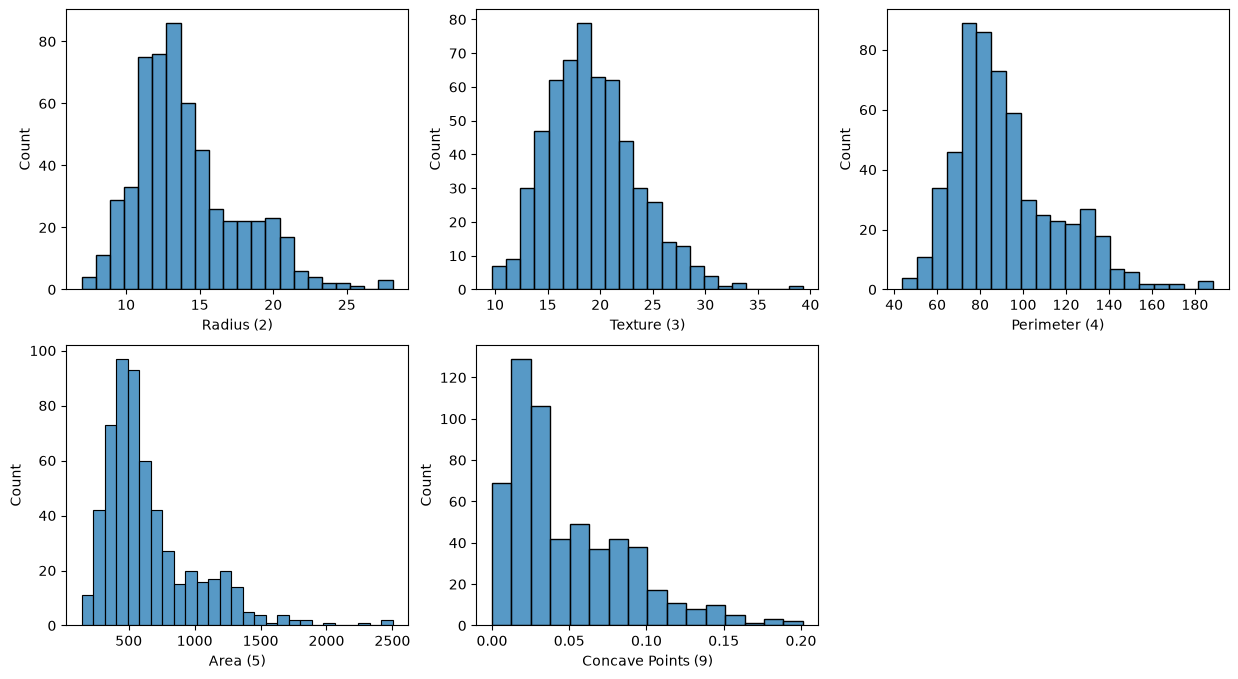

In [20]:
numeric_features = [2, 3, 4, 5, 9]
feature_names = ["Radius (2)", "Texture (3)", "Perimeter (4)", "Area (5)", "Concave Points (9)"]
fig = plt.figure(figsize=(15, 8))
count = 0

for column in numeric_features:
  subfigure = fig.add_subplot(2, 3, count+1)
  subfigure.set_xlabel(feature_names[count])
  sns.histplot(data=df, x=df[column])
  count+=1

plt.show()

## Target Distribution

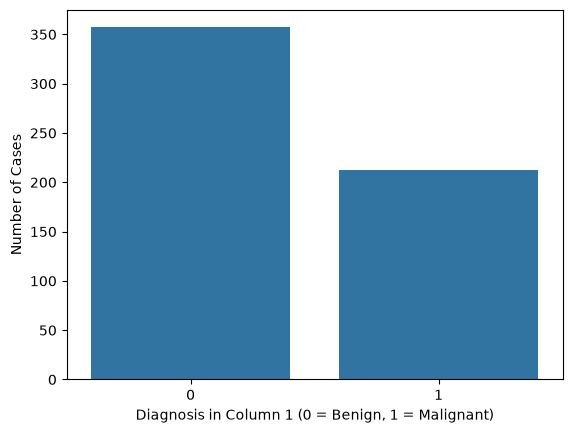

In [21]:
sns.countplot(x=df[1])
plt.xlabel("Diagnosis in Column 1 (0 = Benign, 1 = Malignant)")
plt.ylabel("Number of Cases")
plt.show()

## Numeric Features vs. Target

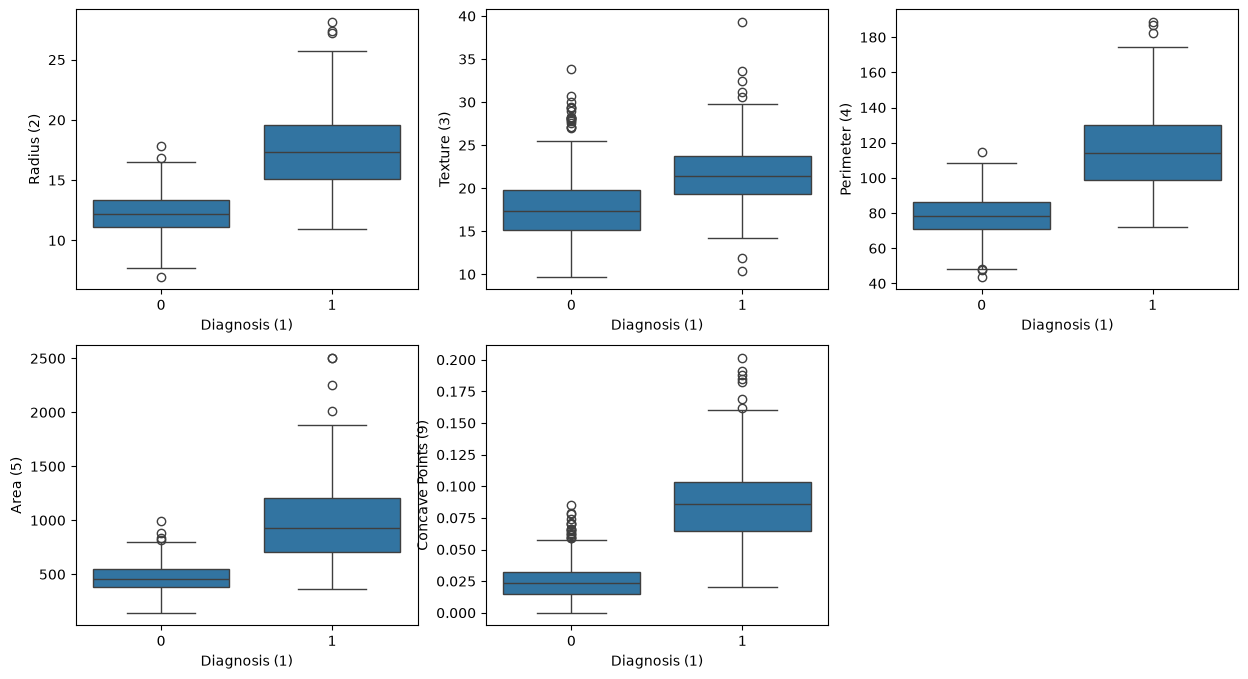

In [22]:
fig = plt.figure(figsize=(15, 8))

for i in range(len(numeric_features)):
  sub = fig.add_subplot(2, 3, i+1)
  sns.boxplot(x=df[1], y=df[numeric_features[i]])
  sub.set_xlabel("Diagnosis (1)")
  sub.set_ylabel(feature_names[i])

plt.show()

I used histograms to see the distributions and box plots to compare benign and malignant tumors. The plots show that malignant tumors usually have larger radius, perimeter, area, and concave point values. The bar chart shows that the dataset contains more benign tumors than malignant tumors.

# Step 3: Split Dataset into Training and Testing Set

The training set is used to train the models, and the testing set is used to evaluate them.

In [23]:
X = df.drop([1], axis=1)
y = df[1]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=97)

print(f"Training data shape: X={X_train.shape}, Y={y_train.shape}")
print(f"Test data shape: X={X_test.shape}, Y={y_test.shape}")

Training data shape: X=(455, 30), Y=(455,)
Test data shape: X=(114, 30), Y=(114,)


# Step 4: Formulate Machine Learning Model Pipeline

In the classification pipeline we will append 6 popular classification algorithms. Logistic Regression is used as the baseline model.

In [24]:
model_pipeline = [] # Declaring empty pipeline
model_pipeline.append(LogisticRegression(solver='liblinear'))
model_pipeline.append(SVC())
model_pipeline.append(KNeighborsClassifier())
model_pipeline.append(DecisionTreeClassifier())
model_pipeline.append(RandomForestClassifier())
model_pipeline.append(GaussianNB())

# Step 5: Model Training and Evaluation

In this step we will iterate through the models performing:
1. Model training,
2. Prediction, and
3. Evaluation

We will calculate commonly used evaluation metrics for classification models: accuracy, ROC & AUC and confusion matrix.

In [25]:
# Declaring empty lists to store performance metrics of each model
accuracy_list=[]
AUC_list=[]
confusion_matrix_list=[]

for model in model_pipeline:
  model.fit(X_train, y_train) # Training the model
  y_pred = model.predict(X_test) # Making predictions on the test set
  accuracy_list.append(round(metrics.accuracy_score(y_test, y_pred),2)) # Adding accuracy of the model to the accuracy list
  false_positive_rate, true_positive_rate, _threshold = metrics.roc_curve(y_test, y_pred)
  AUC_list.append(round(metrics.auc(false_positive_rate, true_positive_rate),2))
  confusion_matrix_list.append(confusion_matrix(y_test, y_pred))

model_list=['Logistic regression', 'SVM', 'KNN', 'Decision Tree', 'Random Forest', 'Naive Bayes']
result_df=pd.DataFrame({'Model':model_list,
                        'Accuracy': accuracy_list,
                        'AUC':AUC_list})
result_df

,Model,Accuracy,AUC
0,Logistic regression,0.95,0.95
1,SVM,0.91,0.90
2,KNN,0.94,0.94
3,Decision Tree,0.94,0.94
4,Random Forest,0.97,0.97
5,Naive Bayes,0.94,0.94


The baseline Logistic Regression model has an accuracy of 0.95 and an AUC of 0.95. The dataset is small, so a different split may produce a different result. The model may be improved by selecting useful features and tuning the model.

**Confusion matrix**

The confusion matrices show the correct and incorrect predictions of each model.

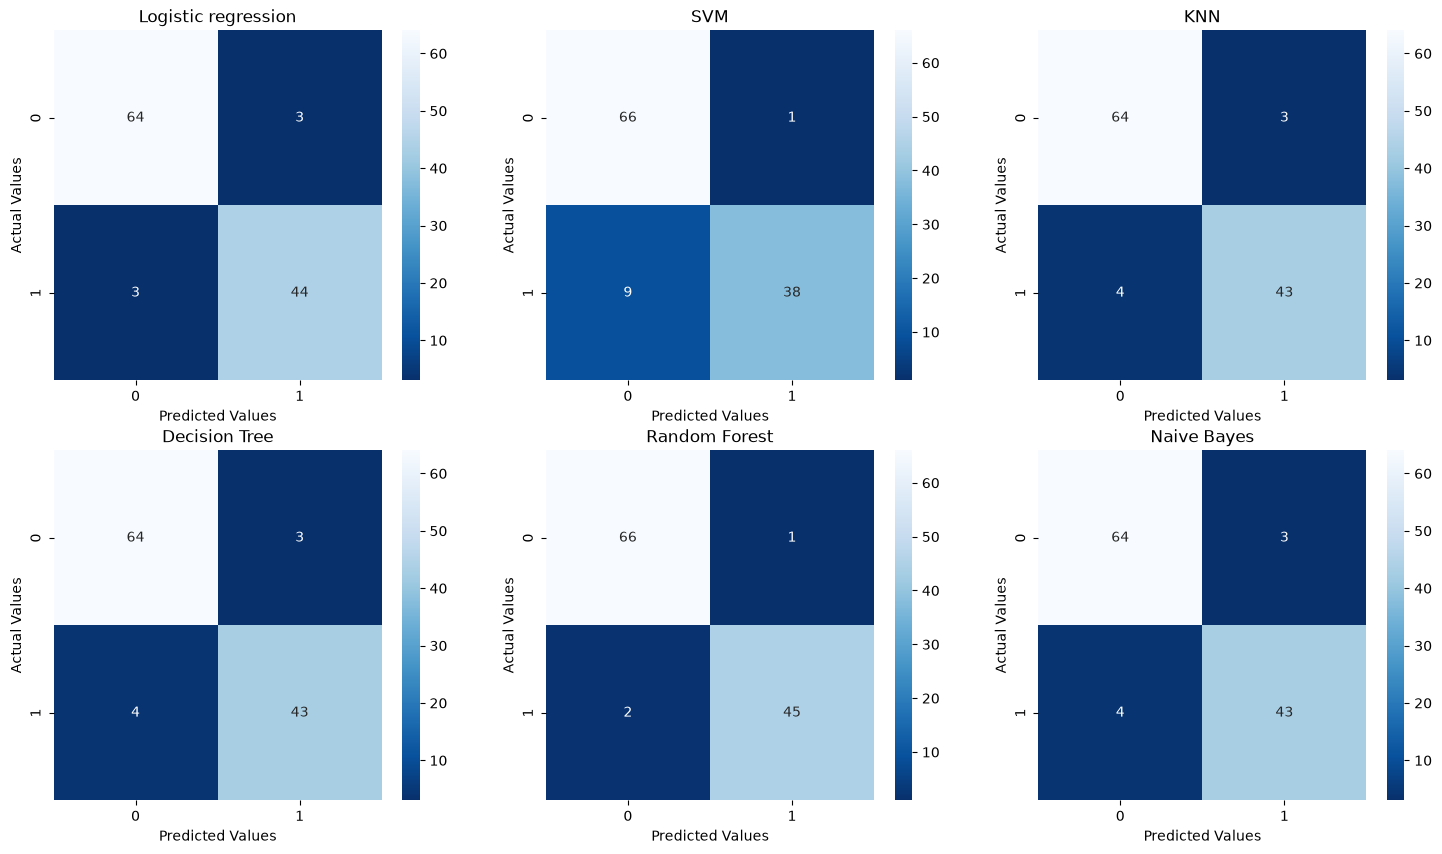

In [26]:
fig = plt.figure(figsize=(18, 10))
for i in range(len(confusion_matrix_list)):
  cm = confusion_matrix_list[i]
  model =model_list[i]
  subfigure=fig.add_subplot(2,3,i+1)
  subfigure.set_title(model)
  cm_plot=sns.heatmap(cm, annot=True, cmap = 'Blues_r') # Seaborn's heatmap to display the confusion matrix
  cm_plot.set_xlabel('Predicted Values')
  cm_plot.set_ylabel('Actual Values')

# Step 6: Hyperparameter Tuning

## Feature Selection

Five features are selected from the plots before training the alternative model.

In [27]:
selected_features = [2, 3, 4, 5, 9]

X = df[selected_features]
y = df[1]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=97)

selected_model = RandomForestClassifier()
selected_model.fit(X_train, y_train)
y_pred = selected_model.predict(X_test)

print("Accuracy after feature selection:", round(metrics.accuracy_score(y_test, y_pred), 2))

Accuracy after feature selection: 0.95


Random Forest is used as the alternative model. GridSearchCV tests different values for the number of trees and the number of features used by each tree.

In [28]:
# define models and parameters
model = RandomForestClassifier()
n_estimators = [10, 100, 1000]
max_features = ['sqrt', 'log2', len(X.columns)]

# define grid search
parameter_grid = {'n_estimators':n_estimators,
                  'max_features':max_features}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1001)
grid_search = GridSearchCV(estimator=model,
                           param_grid=parameter_grid,
                           n_jobs=-1,
                           cv=cv,
                           scoring='accuracy',
                           error_score=0)

grid_result = grid_search.fit(X_train, y_train)
y_pred = grid_result.predict(X_test)

print(f"Best: {grid_result.best_score_} using {grid_result.best_params_}")
print("Accuracy after tuning:", round(metrics.accuracy_score(y_test, y_pred), 2))

Best: 0.9391941391941393 using {'max_features': 'log2', 'n_estimators': 100}
Accuracy after tuning: 0.94


The Random Forest accuracy after feature selection is 0.94. After hyperparameter tuning, its accuracy is 0.94. It does not perform better than the baseline Logistic Regression model.

# Conclusion

Logistic Regression performs well because the data has a fairly clear difference between benign and malignant tumors. Random Forest uses only five selected features, so it may lose useful information and does not perform better after tuning.

# GitHub

I uploaded this project to GitHub: https://github.com/wsmwsj2/DATA555-Project-2/